# E-Commerce Delivery & Regional Performance Analysis
### Olist delivery delay, review scores, and seller state

## 1. Business Question

> **Does delivery delay predict lower customer review scores, and does this
> effect vary meaningfully by seller state/region — which regions should be
> prioritized for logistics review?**

Analysis chain: **delivery delay → customer review score → seller state.**

The analysis establishes *association*, not causation. Wording throughout
uses "associated with" / "linked to".

Reproducible SQL version: `sql/delivery_analysis.sql` (MySQL, same logic).
Final state table: `outputs/state_delivery_analysis.csv`.

## 2. Data Used

Four Olist tables only (from `data/Raw/*.csv`):

| Table | Rows | Role in this analysis |
|---|---|---|
| `orders` | 99,441 | delivery dates → **delivery_delay**; order_status filter |
| `order_items` | 112,650 | links orders → sellers (grain: one row per item) |
| `sellers` | 3,095 | **seller_state** (grain: one row per seller) |
| `order_reviews` | 99,224 | **review_score** (grain: one row per review record) |

No other Olist tables are used (no geolocation, products, payments, customers).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Repo-relative paths: works whether Jupyter starts in the project root or in
# notebooks/ (walks upward until it finds data/Raw).
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'data' / 'Raw').is_dir():
            return p
    raise FileNotFoundError('Project root with data/Raw not found - run from inside the project folder.')

ROOT = find_root()
RAW = str(ROOT / 'data' / 'Raw')
OUT = str(ROOT / 'outputs' / 'state_delivery_analysis.csv')

orders  = pd.read_csv(RAW + r'\olist_orders_dataset.csv')
items   = pd.read_csv(RAW + r'\olist_order_items_dataset.csv')
sellers = pd.read_csv(RAW + r'\olist_sellers_dataset.csv')
reviews = pd.read_csv(RAW + r'\olist_order_reviews_dataset.csv')

print('rows:', {'orders': len(orders), 'order_items': len(items),
                'sellers': len(sellers), 'order_reviews': len(reviews)})
print('\norder_status distribution:')
print(orders.order_status.value_counts())
print('\nreview_score distribution:')
print(reviews.review_score.value_counts().sort_index())
print('\nnulls in delay-relevant columns (delivered orders):')
d = orders[orders.order_status == 'delivered']
print('  delivered rows:', len(d),
      '| null actual date:', d.order_delivered_customer_date.isna().sum(),
      '| null estimated date:', d.order_estimated_delivery_date.isna().sum())

rows: {'orders': 99441, 'order_items': 112650, 'sellers': 3095, 'order_reviews': 99224}

order_status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

review_score distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

nulls in delay-relevant columns (delivered orders):
  delivered rows: 96478 | null actual date: 8 | null estimated date: 0


## 3. Data Quality / Understanding (analysis-relevant only)

- `review_score` range in data: **1–5 integers, no nulls** (valid; nothing invented).
- `order_status`: only `delivered` orders are in scope (96,478); 8 of them have a
  NULL actual delivery date → excluded by the definition below (96,470 usable).
- Date columns are TEXT in the CSVs. Format inspected first:
  `order_delivered_customer_date` → `2017-10-10 21:25:13`,
  `order_estimated_delivery_date` → `2017-10-18 00:00:00` → parsed with the exact
  format `%Y-%m-%d %H:%M:%S`; parsing asserts zero failures before any arithmetic.

## 4. Delivery Delay

**`delivery_delay = order_delivered_customer_date − order_estimated_delivery_date`**

- positive = delivered late, zero = on estimated date, negative = delivered early.
- Filter: `order_status = 'delivered'` AND both dates non-null.
- No rows removed for being zero, negative, or extreme. No winsorizing/capping.

In [2]:
# --- date parsing (format verified in section 3; assert zero parse failures) ---
DATE_FMT = '%Y-%m-%d %H:%M:%S'
for c in ['order_purchase_timestamp', 'order_delivered_customer_date',
          'order_estimated_delivery_date']:
    parsed = pd.to_datetime(orders[c], format=DATE_FMT, errors='coerce')
    bad = orders[c].notna() & parsed.isna()
    assert bad.sum() == 0, f'unparseable {c}'
    orders[c] = parsed

# --- delivery_delay ---
mask = (orders.order_status == 'delivered') & \
       orders.order_delivered_customer_date.notna() & \
       orders.order_estimated_delivery_date.notna()
delivered = orders.loc[mask].copy()
delivered['delivery_delay'] = (delivered.order_delivered_customer_date -
                               delivered.order_estimated_delivery_date).dt.total_seconds() / 86400

print('orders in scope:', len(delivered))
print('min  delay: %8.2f days' % delivered.delivery_delay.min())
print('max  delay: %8.2f days' % delivered.delivery_delay.max())
print('mean delay: %8.2f days' % delivered.delivery_delay.mean())
print('std  delay: %8.2f days' % delivered.delivery_delay.std())
print('early (<0): %d | on time (=0): %d | late (>0): %d'
      % ((delivered.delivery_delay < 0).sum(),
         (delivered.delivery_delay == 0).sum(),
         (delivered.delivery_delay > 0).sum()))

orders in scope: 96470
min  delay:  -146.02 days
max  delay:   188.98 days
mean delay:   -11.18 days
std  delay:    10.18 days
early (<0): 88644 | on time (=0): 0 | late (>0): 7826


In [3]:
# --- extreme cases: verify underlying dates are plausible, not errors ---
cols = ['order_id', 'order_purchase_timestamp', 'order_estimated_delivery_date',
        'order_delivered_customer_date']
print('5 most EARLY deliveries:')
print(delivered.nsmallest(5, 'delivery_delay')[cols].to_string(index=False))
print('\n5 most LATE deliveries:')
print(delivered.nlargest(5, 'delivery_delay')[cols].to_string(index=False))

impossible = (delivered.order_delivered_customer_date < delivered.order_purchase_timestamp).sum()
print('\norders delivered before purchase (data errors):', impossible)
assert impossible == 0
print('-> extremes are internally consistent (purchase <= estimate <= actual); kept as-is.')

5 most EARLY deliveries:
                        order_id order_purchase_timestamp order_estimated_delivery_date order_delivered_customer_date
0607f0efea4b566f1eb8f7d3c2397320      2018-03-06 09:47:07                    2018-08-03           2018-03-09 23:36:47
c72727d29cde4cf870d569bf65edabfd      2017-02-07 18:01:15                    2017-07-04           2017-02-14 14:27:45
eec7f369423b033e549c02f3c5381205      2018-02-06 20:44:56                    2018-07-12           2018-02-27 16:35:43
c2bb89b5c1dd978d507284be78a04cb2      2017-05-23 22:28:36                    2017-10-11           2017-06-09 13:35:54
40dc2ba6f322a17626aac6244332828c      2017-10-05 21:39:05                    2018-01-30           2017-10-13 13:49:07

5 most LATE deliveries:
                        order_id order_purchase_timestamp order_estimated_delivery_date order_delivered_customer_date
1b3190b2dfa9d789e1f14c05b647a14a      2018-02-23 14:57:35                    2018-03-15           2018-09-19 23:24:07
ca0759

## 5. Join / Grain Validation

**Grain of each table (validated, not assumed):**

| Table | Grain | Evidence |
|---|---|---|
| `orders` | 1 row/order | 99,441 rows = 99,441 distinct `order_id` |
| `order_items` | 1 row/item | 112,650 rows / 98,666 orders; up to **21 items/order** |
| `sellers` | 1 row/seller | 3,095 rows = 3,095 distinct `seller_id` |
| `order_reviews` | 1 row/review | 99,224 rows / 98,673 orders; **547 orders have 2–3 review rows** |

A naive 4-table join duplicates orders (items × reviews) and would distort
averages and order volume. **DISTINCT is not used as a fix.** Instead each
source is **pre-aggregated to order grain before joining**:

1. `order_state`: items ⋈ sellers → `GROUP BY order_id` → one `seller_state`
   per order (requires `COUNT(DISTINCT seller_state) = 1`).
   **509 delivered orders span 2–3 states → excluded** (no single home state).
2. `order_review`: `GROUP BY order_id` → mean `review_score`
   (handles the 547 multi-review orders without picking an arbitrary record).
3. Final grain: **one row per delivered order** with delay + state + review;
   inner join also drops the ~768 delivered orders that have no review.

The state metrics therefore represent **orders**, never duplicated item rows.

In [4]:
# --- grain checks on the actual data ---
assert orders.order_id.nunique() == len(orders), 'order_id not unique in orders'
items_per_order  = items.groupby('order_id').size()
reviews_per_order = reviews.groupby('order_id').size()
print('max items per order :', items_per_order.max())
print('orders with >1 review row:', (reviews_per_order > 1).sum(),
      '(max %d)' % reviews_per_order.max())

# row-count impact of the naive joins (documents the duplication problem)
naive = (delivered.merge(items, on='order_id')
                  .merge(reviews[['order_id', 'review_score']], on='order_id'))
print('\ndelivered orders:', len(delivered))
print('rows after naive orders->items->reviews join:', len(naive),
      '(x%.2f vs orders)' % (len(naive) / len(delivered)))

max items per order : 21
orders with >1 review row: 547 (max 3)



delivered orders: 96470
rows after naive orders->items->reviews join: 110005 (x1.14 vs orders)


In [5]:
# --- build the order-grain analytical table (mirrors the SQL CTEs) ---
ist = items.merge(sellers[['seller_id', 'seller_state']], on='seller_id', how='left')
assert ist.seller_state.notna().all()
state_per_order = ist.groupby('order_id')['seller_state'].agg(n_states='nunique',
                                                              seller_state='first')
review_per_order = reviews.groupby('order_id')['review_score'].mean().rename('review_score_order')

grain = delivered[['order_id', 'delivery_delay']].merge(
    state_per_order, left_on='order_id', right_index=True, how='inner').merge(
    review_per_order, left_on='order_id', right_index=True, how='inner')

multi_state = (grain.n_states > 1).sum()
grain = grain[grain.n_states == 1].drop(columns='n_states')

assert grain.order_id.is_unique, 'grain is not one row per order!'
print('order-grain table:', len(grain), 'rows | unique order_id:', grain.order_id.nunique())
print('multi-state delivered orders excluded:', multi_state)
print('=> every later average/count is over ORDERS.')

order-grain table: 95322 rows | unique order_id: 95322
multi-state delivered orders excluded: 502
=> every later average/count is over ORDERS.


## 6. State-Level Results

One row per seller state. `delay_rank` uses **RANK() ordered by average
delivery delay (worst = 1)** — identical definition to the SQL window function.

Notes for reading the table:
- All state averages are **negative**: Olist's estimated dates are conservative,
  most orders arrive before the estimate. `pct_late_orders` (share delivered
  after the estimate) is therefore the sharper delivery-failure measure.
- `pct_low_review` = share of orders whose (order-level) review ≤ 2 stars.

In [6]:
state = grain.groupby('seller_state').agg(
    order_volume=('order_id', 'size'),
    avg_delivery_delay=('delivery_delay', 'mean'),
    pct_late_orders=('delivery_delay', lambda s: 100 * (s > 0).mean()),
    avg_review_score=('review_score_order', 'mean'),
    pct_low_review=('review_score_order', lambda s: 100 * (s <= 2).mean()),
).round({'avg_delivery_delay': 2, 'pct_late_orders': 1,
         'avg_review_score': 3, 'pct_low_review': 1})
state['delay_rank'] = state.avg_delivery_delay.rank(ascending=False, method='min').astype(int)
state = state.sort_values('delay_rank')
print('states:', len(state), '| total orders in analysis:', state.order_volume.sum())
print('(outputs/state_delivery_analysis.csv is exported from the SQL/MySQL run;',
      'validated against it below)')
print(state.to_string())

states: 22 | total orders in analysis: 95322
(outputs/state_delivery_analysis.csv is exported from the SQL/MySQL run; validated against it below)
              order_volume  avg_delivery_delay  pct_late_orders  avg_review_score  pct_low_review  delay_rank
seller_state                                                                                                 
AM                       3                9.35             66.7             2.333            66.7           1
SP                   67741              -10.44              8.7             4.133            13.2           2
PA                       8              -10.57             12.5             4.500             0.0           3
MA                     384              -10.69             22.7             4.018            15.9           4
RJ                    4106              -11.69              8.3             4.253            11.4           5
BA                     543              -11.92              5.7             4.206   

In [7]:
# --- is delay associated with review score? (order level) ---
def band(x):
    if x <= -7:  return '1. very early (<= -7d)'
    if x <= 0:   return '2. early/on-time (-7d..0d)'
    if x <= 3:   return '3. late 1-3d'
    if x <= 7:   return '4. late 4-7d'
    if x <= 14:  return '5. late 8-14d'
    return '6. late 15d+'

bands = grain.assign(delay_band=grain.delivery_delay.map(band)).groupby('delay_band').agg(
    n_orders=('order_id', 'size'),
    avg_delay=('delivery_delay', 'mean'),
    avg_review_score=('review_score_order', 'mean'),
    pct_low_review=('review_score_order', lambda s: 100 * (s <= 2).mean())).round(2)
print('Review performance by delivery-delay band (order grain):')
print(bands.to_string())

Review performance by delivery-delay band (order grain):
                            n_orders  avg_delay  avg_review_score  pct_low_review
delay_band                                                                       
1. very early (<= -7d)         70456     -15.13              4.33            8.67
2. early/on-time (-7d..0d)     17209      -4.16              4.20           10.16
3. late 1-3d                    2634       1.40              3.77           19.02
4. late 4-7d                    1771       5.11              2.32           61.21
5. late 8-14d                   1748       9.97              1.75           78.03
6. late 15d+                    1504      28.04              1.71           78.66


## 7. Priority States

**Minimum-volume threshold: `order_volume >= 1000`.**
Justification: volumes are extremely skewed (SP 67,741 vs AM 3). The
1,000-order cut leaves **6 states = 92,065 of 95,322 analyzed orders (96.6%)**;
below it, averages are dominated by a handful of orders (AM: 3 orders,
avg review 2.33 — meaningless). All 22 states remain in the CSV; small states
are simply flagged as small-sample, not deleted.

In [8]:
eligible = state[state.order_volume >= 1000].copy()
print('eligible states (>=1000 orders):')
print(eligible.to_string())
print('\ncoverage: %d of %d analyzed orders (%.1f%%)'
      % (eligible.order_volume.sum(), state.order_volume.sum(),
         100 * eligible.order_volume.sum() / state.order_volume.sum()))

print('\nState-level association between delivery delay and review score:')
print('  Pearson r (avg_delivery_delay vs avg_review_score), all 22 states : %.2f'
      % state.avg_delivery_delay.corr(state.avg_review_score))
print('  Pearson r, 6 eligible states                                      : %.2f'
      % eligible.avg_delivery_delay.corr(eligible.avg_review_score))

# Selection is documented, not hidden in a composite score:
#  - delivery-side worst 3 eligible (by avg delay): SP, RJ, MG
#  - review-side worst 3 eligible (by avg review): SP, SC, PR
#  Final priorities = SP (on both lists) + RJ (delivery side) + SC (review side);
#  PR (tied with SC on reviews) noted as close fourth. RS = reference (best both).
delivery_side = eligible.nlargest(3, 'avg_delivery_delay')     # latest avg delay
review_side   = eligible.nsmallest(3, 'avg_review_score')      # worst reviews
ref = eligible.avg_review_score.idxmax()   # reference = best review among eligible

print('delivery-side candidates (worst avg delay among eligible):')
print(delivery_side.to_string())
print('\nreview-side candidates (worst avg review among eligible):')
print(review_side.to_string())
print('\nreference state (best among eligible):', ref)
print(state.loc[[ref]].to_string())

eligible states (>=1000 orders):
              order_volume  avg_delivery_delay  pct_late_orders  avg_review_score  pct_low_review  delay_rank
seller_state                                                                                                 
SP                   67741              -10.44              8.7             4.133            13.2           2
RJ                    4106              -11.69              8.3             4.253            11.4           5
MG                    7517              -12.65              5.5             4.256            10.1          11
SC                    3495              -13.31              6.0             4.209            11.8          13
PR                    7296              -13.35              6.5             4.213            11.7          14
RS                    1910              -15.52              4.3             4.346             8.2          18

coverage: 92065 of 95322 analyzed orders (96.6%)

State-level association between deli

In [9]:
# --- cross-check: pandas notebook results == MySQL SQL export (deliverable CSV) ---
# The CSV is produced from sql/delivery_analysis.sql via MySQL; this independent
# pandas computation must reproduce it exactly. (Skipped if CSV not yet exported.)
import os
if os.path.exists(OUT):
    csv = pd.read_csv(OUT).set_index('seller_state').sort_index()
    mine = state.sort_index()
    assert list(csv.index) == list(mine.index), 'state sets differ'
    for c in ['order_volume', 'avg_delivery_delay', 'pct_late_orders',
              'avg_review_score', 'pct_low_review', 'delay_rank']:
        diff = (csv[c] - mine[c]).abs().max()
        assert diff < 1e-9, f'{c} mismatch: {diff}'
    print('OK - pandas notebook results match outputs/state_delivery_analysis.csv (from SQL/MySQL), all columns.')
else:
    print('CSV not found; export it first by running sql/delivery_analysis.sql.')

OK - pandas notebook results match outputs/state_delivery_analysis.csv (from SQL/MySQL), all columns.


### Priority-state numbers vs reference

| State | Role | avg delay (d) | late orders | avg review | 1–2★ share | volume | delay rank |
|---|---|---|---|---|---|---|---|
| **SP** | priority 1 | −10.44 | 8.7% | 4.133 | 13.2% | 67,741 | 2 / 22 |
| **RJ** | priority 2 | −11.69 | 8.3% | 4.253 | 11.4% | 4,106 | 5 / 22 |
| **SC** | priority 3 | −13.31 | 6.0% | 4.209 | 11.8% | 3,495 | 13 / 22 |
| RS | reference (best eligible) | −15.52 | 4.3% | 4.346 | 8.2% | 1,910 | 18 / 22 |

Why these: SP is worst among eligible states on **all** of delay, late share,
review score and low-review share, with 71% of analyzed volume. RJ is
2nd-worst on delivery (delay rank 5, 8.3% late). SC has the 2nd-lowest review
score among eligible states. PR (7,296 orders, 4.213 review, 6.5% late) is
effectively tied with SC and should be treated as a close fourth.
Near-threshold watch items (small samples, flagged not ranked): MA
(384 orders, 22.7% late, review 4.018) and DF (799 orders, review 4.106).

## 8. Business Finding

**1. Is delivery delay associated with lower review scores? — Yes, strongly, at order level.**
Orders delivered early/on time average **4.20–4.33** stars. Orders 1–3 days late
average **3.77**; 4–7 days late **2.32**; 8–14 days late **1.75**; 15+ days late
**1.71**. The 1–2★ share rises from **8.7–10.2%** (early/on time) to **61.2%**
(4–7 days late) and **~78%** (8+ days late).

**2. Does the pattern vary by seller state? — Yes.** Across states, higher
average delay is associated with lower average review score
(r = −0.75 across all 22 states; r = −0.82 across the six states with ≥1,000
orders — small n, directional evidence).

**3. Magnitude between states.** SP delivers **5.08 days later** on average than
RS (−10.44 vs −15.52 days), has **8.7% vs 4.3% late orders**, and scores
**4.133 vs 4.346** average reviews with **13.2% vs 8.2%** 1–2★ reviews
(+5.0 pp ≈ 60% higher share of poor reviews) across **67,741 orders**.

**Conclusion (association, not causation):** Orders delivered later are
associated with markedly lower review scores, and among high-volume seller
states SP combines the latest relative delivery (8.7% of 67,741 orders late,
delay rank 2/22) with the lowest review score (4.133 vs the 4.346 best-state
reference), indicating a meaningful association between delivery performance
and customer satisfaction — **prioritize SP for logistics review first**, then
RJ (delay rank 5, 8.3% late) and SC (review 4.209), with PR as a close fourth.

### Optional visual — state delivery performance vs review score

saved: outputs/state_delivery_review_scatter.png


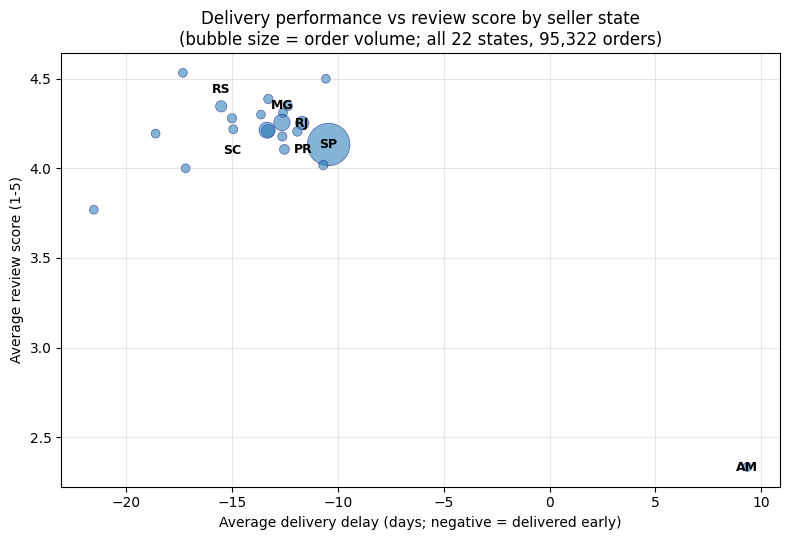

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sizes = 40 + 900 * (state.order_volume / state.order_volume.max())
ax.scatter(state.avg_delivery_delay, state.avg_review_score, s=sizes,
           alpha=0.55, edgecolors='navy', linewidths=0.5)
# label key states; offset SC/PR (nearly identical values) so labels don't collide
label_cfg = {'SP': (0, 0), 'RJ': (0, 0), 'MG': (0, 12), 'RS': (0, 12),
             'AM': (0, 0), 'SC': (-26, -14), 'PR': (26, -14)}
for st, (dx, dy) in label_cfg.items():
    row = state.loc[st]
    ax.annotate(st, (row.avg_delivery_delay, row.avg_review_score),
                textcoords='offset points', xytext=(dx, dy),
                fontsize=9, fontweight='bold', ha='center', va='center')
ax.set_xlabel('Average delivery delay (days; negative = delivered early)')
ax.set_ylabel('Average review score (1-5)')
ax.set_title('Delivery performance vs review score by seller state\n(bubble size = order volume; all 22 states, 95,322 orders)')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(str(ROOT / 'outputs' / 'state_delivery_review_scatter.png'), dpi=150)
print('saved: outputs/state_delivery_review_scatter.png')